# 🧪 Cleaning and preparing airline passenger satisfaction dataset 

This dataset was downloaded from  Kaggle: https://www.kaggle.com/datasets/teejmahal20/airline-passenger-satisfaction. It was modified from the dataset by John D. https://www.kaggle.com/datasets/johndddddd/customer-satisfaction for classification.

This dataset contains an airline passenger satisfaction survey. The raw dataset contains 25,976 instances and 25 comlumns. It is cleaned, preprocessed, and prepared in this notebook. After this phase of data preparation, a final dataset with 25,893 instances and 27 input attributes is obtained. The file SatisfactionPreparedCleanAttributes.csv contains the resulting input data.

The classification problem is to predict passenger satisfaction as one of two possible one-hot encoded classes: *satisfied* or *neutral or dissatisfied*. The resulting file is SatisfactionOneHotEncodedClasses.csv.

In [6]:
%pip install pandas scikit-learn matplotlib seaborn bokeh

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.4/6.4 MB 9.7 MB/s  0:00:006m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [bokeh]32m2/3 [bokeh]ls]

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [7]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import LabelEncoder, OneHotEncoder, minmax_scale, scale

import matplotlib.pyplot as plt
import seaborn as sns
import bokeh as bk

#### Load data

In [8]:
INPUT_FILE_NAME = "SatisfactionRawDataset.csv"
ATT_FILE_NAME = "SatisfactionPreparedCleanAttributes.csv"
BINARY_ENCODED_CLASSES_FILE_NAME = "SatisfactionBinaryEncodedClasses.csv"

In [9]:
dataset = pd.read_csv(INPUT_FILE_NAME)
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25976 entries, 0 to 25975
Data columns (total 25 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Unnamed: 0                         25976 non-null  int64  
 1   id                                 25976 non-null  int64  
 2   Gender                             25976 non-null  object 
 3   Customer Type                      25976 non-null  object 
 4   Age                                25976 non-null  int64  
 5   Type of Travel                     25976 non-null  object 
 6   Class                              25976 non-null  object 
 7   Flight Distance                    25976 non-null  int64  
 8   Inflight wifi service              25976 non-null  int64  
 9   Departure/Arrival time convenient  25976 non-null  int64  
 10  Ease of Online booking             25976 non-null  int64  
 11  Gate location                      25976 non-null  int

The *Arrival Delay in Minutes* variable has 83 non-numeric values. Since there are so few, we drop them and convert the remaining to int64.

In [10]:
{att : dataset[dataset[att].isnull()].shape[0] for att in dataset.columns}

{'Unnamed: 0': 0,
 'id': 0,
 'Gender': 0,
 'Customer Type': 0,
 'Age': 0,
 'Type of Travel': 0,
 'Class': 0,
 'Flight Distance': 0,
 'Inflight wifi service': 0,
 'Departure/Arrival time convenient': 0,
 'Ease of Online booking': 0,
 'Gate location': 0,
 'Food and drink': 0,
 'Online boarding': 0,
 'Seat comfort': 0,
 'Inflight entertainment': 0,
 'On-board service': 0,
 'Leg room service': 0,
 'Baggage handling': 0,
 'Checkin service': 0,
 'Inflight service': 0,
 'Cleanliness': 0,
 'Departure Delay in Minutes': 0,
 'Arrival Delay in Minutes': 83,
 'satisfaction': 0}

In [11]:
dataset.dropna(inplace=True)
dataset["Arrival Delay in Minutes"] = dataset["Arrival Delay in Minutes"].astype("int64")
dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 25893 entries, 0 to 25975
Data columns (total 25 columns):
 #   Column                             Non-Null Count  Dtype 
---  ------                             --------------  ----- 
 0   Unnamed: 0                         25893 non-null  int64 
 1   id                                 25893 non-null  int64 
 2   Gender                             25893 non-null  object
 3   Customer Type                      25893 non-null  object
 4   Age                                25893 non-null  int64 
 5   Type of Travel                     25893 non-null  object
 6   Class                              25893 non-null  object
 7   Flight Distance                    25893 non-null  int64 
 8   Inflight wifi service              25893 non-null  int64 
 9   Departure/Arrival time convenient  25893 non-null  int64 
 10  Ease of Online booking             25893 non-null  int64 
 11  Gate location                      25893 non-null  int64 
 12  Food and 

In [12]:
print(dataset.shape)
dataset.head()

(25893, 25)


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,19556,Female,Loyal Customer,52,Business travel,Eco,160,5,4,...,5,5,5,5,2,5,5,50,44,satisfied
1,1,90035,Female,Loyal Customer,36,Business travel,Business,2863,1,1,...,4,4,4,4,3,4,5,0,0,satisfied
2,2,12360,Male,disloyal Customer,20,Business travel,Eco,192,2,0,...,2,4,1,3,2,2,2,0,0,neutral or dissatisfied
3,3,77959,Male,Loyal Customer,44,Business travel,Business,3377,0,0,...,1,1,1,1,3,1,4,0,6,satisfied
4,4,36875,Female,Loyal Customer,49,Business travel,Eco,1182,2,3,...,2,2,2,2,4,2,4,0,20,satisfied


#### Remove Unnamed: 0 and student_id columns (variables), as they do not contribute predictive value.

In [13]:
dataset.drop(columns=['Unnamed: 0'], inplace=True)
dataset.drop(columns=['id'], inplace=True)

#### Put all qualitative variable labels in lowercase to avoid inconsistencies.

In [14]:
for col in ['Gender','Customer Type','Type of Travel','Class','satisfaction']:
    if col in dataset.columns:
        dataset[col] = dataset[col].astype(str).str.strip().str.lower()
dataset[:10]

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,female,loyal customer,52,business travel,eco,160,5,4,3,4,...,5,5,5,5,2,5,5,50,44,satisfied
1,female,loyal customer,36,business travel,business,2863,1,1,3,1,...,4,4,4,4,3,4,5,0,0,satisfied
2,male,disloyal customer,20,business travel,eco,192,2,0,2,4,...,2,4,1,3,2,2,2,0,0,neutral or dissatisfied
3,male,loyal customer,44,business travel,business,3377,0,0,0,2,...,1,1,1,1,3,1,4,0,6,satisfied
4,female,loyal customer,49,business travel,eco,1182,2,3,4,3,...,2,2,2,2,4,2,4,0,20,satisfied
5,male,loyal customer,16,business travel,eco,311,3,3,3,3,...,5,4,3,1,1,2,5,0,0,satisfied
6,female,loyal customer,77,business travel,business,3987,5,5,5,5,...,5,5,5,5,4,5,3,0,0,satisfied
7,female,loyal customer,43,business travel,business,2556,2,2,2,2,...,4,4,4,4,5,4,3,77,65,satisfied
8,male,loyal customer,47,business travel,eco,556,5,2,2,2,...,5,2,2,5,3,3,5,1,0,satisfied
9,female,loyal customer,46,business travel,business,1744,2,2,2,2,...,4,4,4,4,5,4,4,28,14,satisfied


#### Outliers:
*Flight Distance* values greater than 3700 and *Departure* and *Arrival Delay Minutes* greater than 180 are outliers.


<Axes: >

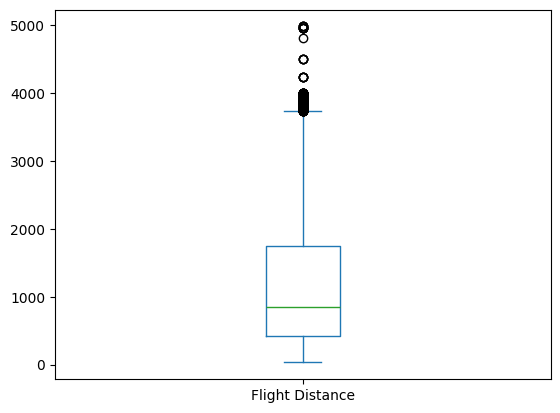

In [15]:
dataset['Flight Distance'].plot(kind="box")

<Axes: >

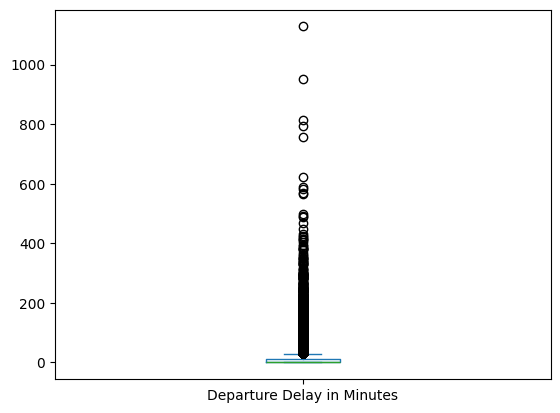

In [16]:
dataset['Departure Delay in Minutes'].plot(kind="box")

<Axes: >

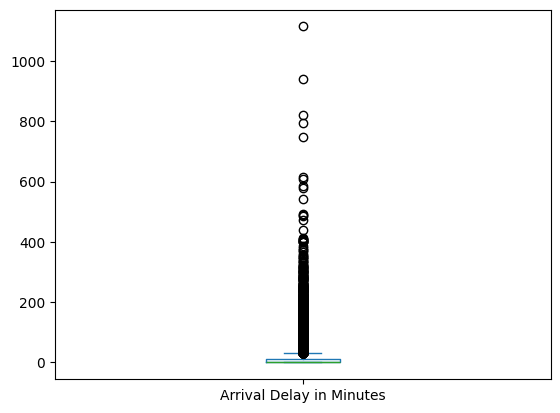

In [17]:
dataset['Arrival Delay in Minutes'].plot(kind="box")

In [18]:
dataset["Flight Distance"] = dataset["Flight Distance"].clip(upper=3700)
dataset["Departure Delay in Minutes"] = dataset["Departure Delay in Minutes"].clip(upper=30)
dataset["Arrival Delay in Minutes"] = dataset["Arrival Delay in Minutes"].clip(upper=30)

<Axes: >

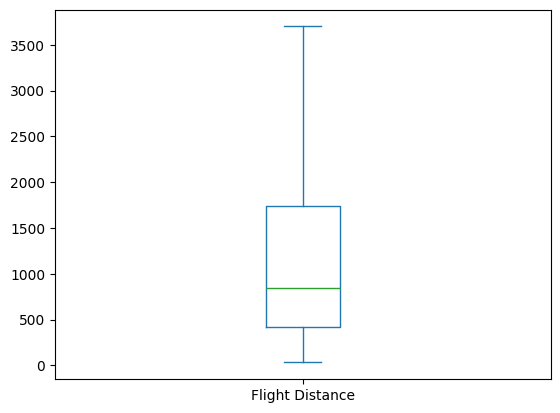

In [19]:
dataset['Flight Distance'].plot(kind="box")

<Axes: >

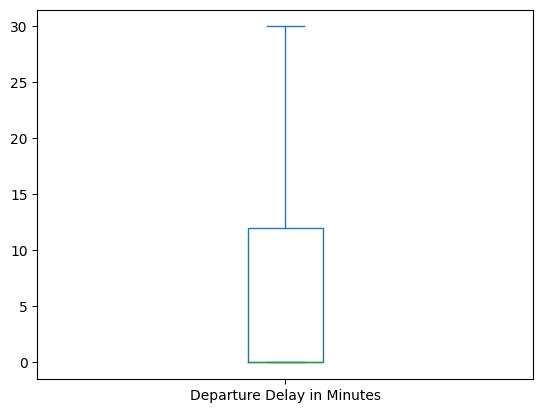

In [20]:
dataset['Departure Delay in Minutes'].plot(kind="box")

<Axes: >

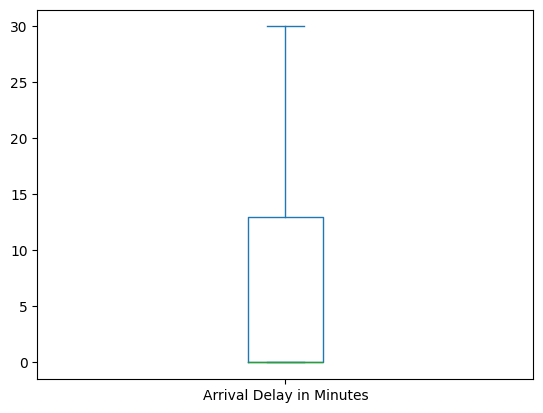

In [21]:
dataset['Arrival Delay in Minutes'].plot(kind="box")

#### Qualitative variables codification:

In [22]:
dataset['Gender'].value_counts()

Gender
female    13127
male      12766
Name: count, dtype: int64

In [23]:
dataset['Customer Type'].value_counts()

Customer Type
loyal customer       21111
disloyal customer     4782
Name: count, dtype: int64

In [24]:
dataset['Type of Travel'].value_counts()

Type of Travel
business travel    17980
personal travel     7913
Name: count, dtype: int64

In [25]:
dataset['Class'].value_counts()

Class
business    12457
eco         11524
eco plus     1912
Name: count, dtype: int64

In [26]:
dataset['satisfaction'].value_counts() 

satisfaction
neutral or dissatisfied    14528
satisfied                  11365
Name: count, dtype: int64

No variable with qualitative values establishes an order. Therefore, they are one-hot encoded, except for the target variable satisfaction:

In [27]:
dataset = pd.get_dummies(dataset, columns=['Gender'], drop_first=False, dtype=int)
dataset = pd.get_dummies(dataset, columns=['Customer Type'], drop_first=False, dtype=int)
dataset = pd.get_dummies(dataset, columns=['Type of Travel'], drop_first=False, dtype=int)
dataset = pd.get_dummies(dataset, columns=['Class'], drop_first=False, dtype=int)
dataset[:10]

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,satisfaction,Gender_female,Gender_male,Customer Type_disloyal customer,Customer Type_loyal customer,Type of Travel_business travel,Type of Travel_personal travel,Class_business,Class_eco,Class_eco plus
0,52,160,5,4,3,4,3,4,3,5,...,satisfied,1,0,0,1,1,0,0,1,0
1,36,2863,1,1,3,1,5,4,5,4,...,satisfied,1,0,0,1,1,0,1,0,0
2,20,192,2,0,2,4,2,2,2,2,...,neutral or dissatisfied,0,1,1,0,1,0,0,1,0
3,44,3377,0,0,0,2,3,4,4,1,...,satisfied,0,1,0,1,1,0,1,0,0
4,49,1182,2,3,4,3,4,1,2,2,...,satisfied,1,0,0,1,1,0,0,1,0
5,16,311,3,3,3,3,5,5,3,5,...,satisfied,0,1,0,1,1,0,0,1,0
6,77,3700,5,5,5,5,3,5,5,5,...,satisfied,1,0,0,1,1,0,1,0,0
7,43,2556,2,2,2,2,4,4,5,4,...,satisfied,1,0,0,1,1,0,1,0,0
8,47,556,5,2,2,2,5,5,5,5,...,satisfied,0,1,0,1,1,0,0,1,0
9,46,1744,2,2,2,2,3,4,4,4,...,satisfied,1,0,0,1,1,0,1,0,0


We codify *satisfaction* as satisfied->1; neutral or dissatisfied ->0:

In [28]:
dataset['satisfaction'] = dataset['satisfaction'].replace({'satisfied': '1', 'neutral or dissatisfied': '0'}).astype('int64')
dataset.satisfaction[:10] 

0    1
1    1
2    0
3    1
4    1
5    1
6    1
7    1
8    1
9    1
Name: satisfaction, dtype: int64

It is verified that there are no null values after the encoding process:

In [29]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 25893 entries, 0 to 25975
Data columns (total 28 columns):
 #   Column                             Non-Null Count  Dtype
---  ------                             --------------  -----
 0   Age                                25893 non-null  int64
 1   Flight Distance                    25893 non-null  int64
 2   Inflight wifi service              25893 non-null  int64
 3   Departure/Arrival time convenient  25893 non-null  int64
 4   Ease of Online booking             25893 non-null  int64
 5   Gate location                      25893 non-null  int64
 6   Food and drink                     25893 non-null  int64
 7   Online boarding                    25893 non-null  int64
 8   Seat comfort                       25893 non-null  int64
 9   Inflight entertainment             25893 non-null  int64
 10  On-board service                   25893 non-null  int64
 11  Leg room service                   25893 non-null  int64
 12  Baggage handling       

Now that all variables are numerical, descriptive statistics are displayed.

#### Statistics

In [30]:
dataset.describe()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,satisfaction,Gender_female,Gender_male,Customer Type_disloyal customer,Customer Type_loyal customer,Type of Travel_business travel,Type of Travel_personal travel,Class_business,Class_eco,Class_eco plus
count,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000,...,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000
mean,39.621983,1189.249411,2.723709,3.046422,2.755996,2.976442,3.214923,3.261615,3.448886,3.356969,...,0.438922,0.506971,0.493029,0.184683,0.815317,0.694396,0.305604,0.481095,0.445062,0.073842
std,15.134224,986.448695,1.334711,1.532971,1.412552,1.281661,1.331895,1.355505,1.320254,1.338643,...,0.496265,0.499961,0.499961,0.388048,0.388048,0.460672,0.460672,0.499652,0.496982,0.261519
min,7.000000,31.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,27.000000,414.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,40.000000,849.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,...,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
75%,51.000000,1744.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,4.000000,...,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
max,85.000000,3700.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


The **correlation matrix** allows visualization of dependencies between pairs of attributes: values close to -1 or +1 indicate a high correlation. A negative correlation value means that when the value of one attribute increases, the value of the other decreases, and vice versa. Positive correlation values point out that both features increase or decrease simultaneously. 

In [31]:
dataset.corr()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,satisfaction,Gender_female,Gender_male,Customer Type_disloyal customer,Customer Type_loyal customer,Type of Travel_business travel,Type of Travel_personal travel,Class_business,Class_eco,Class_eco plus
Age,1.000000,0.099891,0.009116,0.031898,0.013728,0.002677,0.024613,0.202648,0.154878,0.069480,...,0.121756,-0.009222,0.009222,-0.294139,0.294139,0.030018,-0.030018,0.138213,-0.133393,-0.010570
Flight Distance,0.099891,1.000000,0.004909,-0.014503,0.062495,0.008343,0.058085,0.215589,0.159785,0.138744,...,0.296207,0.005412,-0.005412,-0.230030,0.230030,0.265271,-0.265271,0.466630,-0.402437,-0.126754
Inflight wifi service,0.009116,0.004909,1.000000,0.349135,0.711115,0.348154,0.122242,0.459132,0.116454,0.201438,...,0.279884,0.005954,-0.005954,0.001359,-0.001359,0.108399,-0.108399,0.038730,-0.037323,-0.003068
Departure/Arrival time convenient,0.031898,-0.014503,0.349135,1.000000,0.440375,0.458575,-0.015291,0.080899,-0.002014,-0.022097,...,-0.065266,-0.008485,0.008485,-0.206527,0.206527,-0.246689,0.246689,-0.082809,0.070061,0.025071
Ease of Online booking,0.013728,0.062495,0.711115,0.440375,1.000000,0.465729,0.025494,0.408320,0.022989,0.044636,...,0.157634,-0.002021,0.002021,-0.012484,0.012484,0.135869,-0.135869,0.112156,-0.102995,-0.018554
Gate location,0.002677,0.008343,0.348154,0.458575,0.465729,1.000000,-0.009410,0.007060,-0.001054,-0.000478,...,-0.016350,0.005138,-0.005138,-0.001890,0.001890,0.026204,-0.026204,0.012211,-0.011855,-0.000802
Food and drink,0.024613,0.058085,0.122242,-0.015291,0.025494,-0.009410,1.000000,0.229630,0.581687,0.627343,...,0.217098,0.014657,-0.014657,-0.047509,0.047509,0.091127,-0.091127,0.103055,-0.086458,-0.032592
Online boarding,0.202648,0.215589,0.459132,0.080899,0.408320,0.007060,0.229630,1.000000,0.415573,0.279317,...,0.494322,0.055609,-0.055609,-0.188781,0.188781,0.220383,-0.220383,0.332345,-0.291292,-0.081409
Seat comfort,0.154878,0.159785,0.116454,-0.002014,0.022989,-0.001054,0.581687,0.415573,1.000000,0.617282,...,0.346398,0.047656,-0.047656,-0.143126,0.143126,0.141039,-0.141039,0.238068,-0.200894,-0.073074
Inflight entertainment,0.069480,0.138744,0.201438,-0.022097,0.044636,-0.000478,0.627343,0.279317,0.617282,1.000000,...,0.398884,0.005255,-0.005255,-0.090487,0.090487,0.171648,-0.171648,0.214299,-0.179833,-0.067686


It is interesting to observe that variables *Online boarding*, *Seat comfort*, *Inflight entertainment*, *business travel*, and *business class* are correlated with *satisfaction*. 

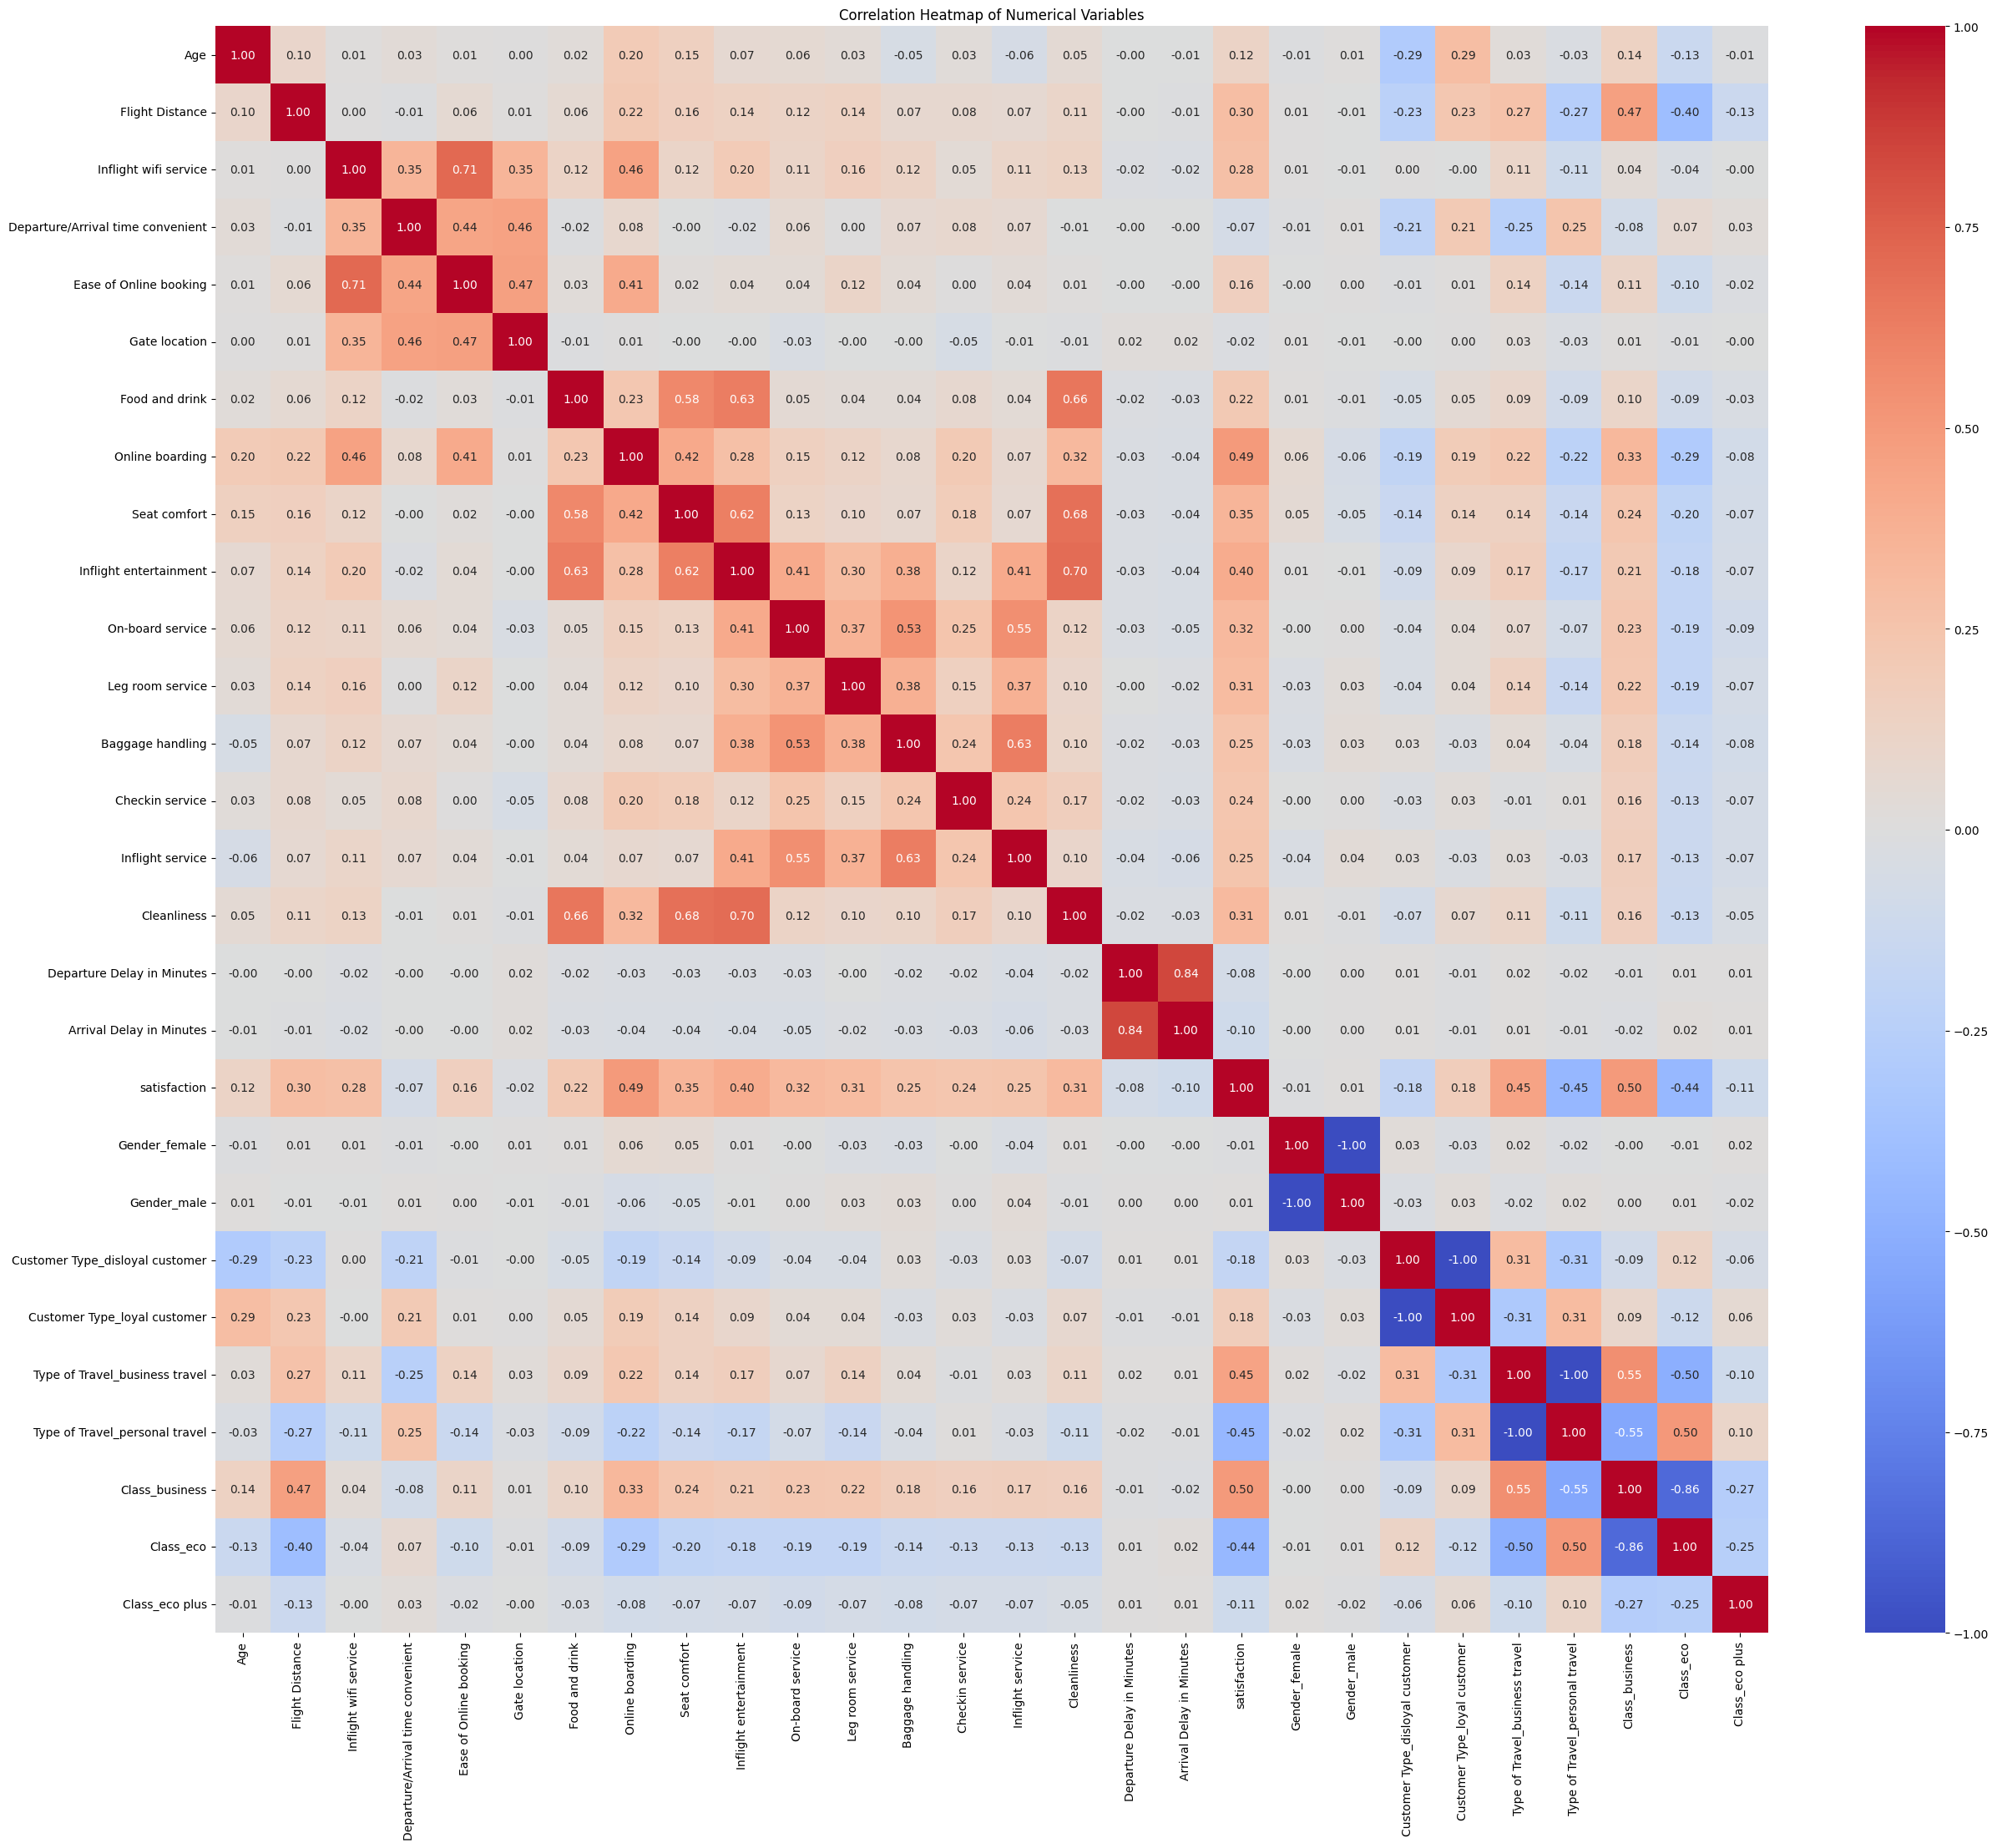

In [32]:
correlation_matrix = dataset.corr()
plt.figure(figsize=(30, 25))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap of Numerical Variables')
plt.show()

#### Shuffle the dataset.

In [33]:
#frac is the fraction of axis items to return. 1 means all of them
dataset=dataset.sample(frac=1).reset_index(drop=True) #Reset index and drop the old one
dataset.head()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,satisfaction,Gender_female,Gender_male,Customer Type_disloyal customer,Customer Type_loyal customer,Type of Travel_business travel,Type of Travel_personal travel,Class_business,Class_eco,Class_eco plus
0,38,679,3,4,3,3,4,3,1,4,...,0,0,1,0,1,0,1,0,1,0
1,44,438,4,2,2,2,4,4,4,4,...,1,0,1,0,1,1,0,0,1,0
2,68,994,3,4,3,3,2,3,2,2,...,0,0,1,0,1,0,1,0,1,0
3,49,1072,2,2,4,2,2,4,5,4,...,1,1,0,0,1,1,0,1,0,0
4,41,776,4,4,2,4,4,4,4,4,...,1,0,1,0,1,1,0,0,1,0


The number of instances per label should be balanced.

In [34]:
dataset['satisfaction'].value_counts() 

satisfaction
0    14528
1    11365
Name: count, dtype: int64

#### Split the dataset vertically into attributes $x$ and label $t$ for supervised learning.

In [35]:
binary_t = pd.DataFrame(data=dataset["satisfaction"].values,columns=["Satisfaction"])
binary_t[:10]

,Satisfaction
0,0
1,1
2,0
3,1
4,1
5,1
6,1
7,1
8,0
9,0


In [36]:
x = dataset.drop (columns="satisfaction")
x.head()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Arrival Delay in Minutes,Gender_female,Gender_male,Customer Type_disloyal customer,Customer Type_loyal customer,Type of Travel_business travel,Type of Travel_personal travel,Class_business,Class_eco,Class_eco plus
0,38,679,3,4,3,3,4,3,1,4,...,0,0,1,0,1,0,1,0,1,0
1,44,438,4,2,2,2,4,4,4,4,...,9,0,1,0,1,1,0,0,1,0
2,68,994,3,4,3,3,2,3,2,2,...,5,0,1,0,1,0,1,0,1,0
3,49,1072,2,2,4,2,2,4,5,4,...,4,1,0,0,1,1,0,1,0,0
4,41,776,4,4,2,4,4,4,4,4,...,19,0,1,0,1,1,0,0,1,0


#### Standardize or normalize the input dataset. 
*Standardization* is much less affected by outliers, but it does not bound values to a specific range, which may be a problem for neural networks. The center is the mean, and the data is scaled to unit variance. On the other hand, *min-max scaling* ranges the data within min and max values, usually -1 and 1 or \[0,1\].  

In [37]:
x = pd.DataFrame (minmax_scale (x, feature_range=(0,1)),columns=x.columns)
x[:10]

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Arrival Delay in Minutes,Gender_female,Gender_male,Customer Type_disloyal customer,Customer Type_loyal customer,Type of Travel_business travel,Type of Travel_personal travel,Class_business,Class_eco,Class_eco plus
0,0.397436,0.176615,0.6,0.8,0.6,0.50,0.8,0.6,0.00,0.8,...,0.000000,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
1,0.474359,0.110929,0.8,0.4,0.4,0.25,0.8,0.8,0.75,0.8,...,0.300000,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
2,0.782051,0.262469,0.6,0.8,0.6,0.50,0.4,0.6,0.25,0.4,...,0.166667,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
3,0.538462,0.283729,0.4,0.4,0.8,0.25,0.4,0.8,1.00,0.8,...,0.133333,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
4,0.435897,0.203053,0.8,0.8,0.4,0.75,0.8,0.8,0.75,0.8,...,0.633333,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
5,0.192308,0.106841,1.0,0.0,1.0,0.25,0.6,1.0,0.50,0.6,...,0.566667,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
6,0.525641,0.332243,0.8,0.8,0.8,0.75,0.8,0.2,0.50,1.0,...,0.000000,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
7,0.384615,0.260289,0.8,0.8,0.8,0.75,1.0,1.0,0.75,0.8,...,0.133333,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
8,0.371795,0.055328,0.6,0.6,0.6,0.50,0.8,0.6,0.75,0.8,...,0.000000,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
9,0.346154,0.227855,0.8,1.0,1.0,0.75,0.2,1.0,0.00,0.2,...,1.000000,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0


#### Boxplot attributes

<Axes: >

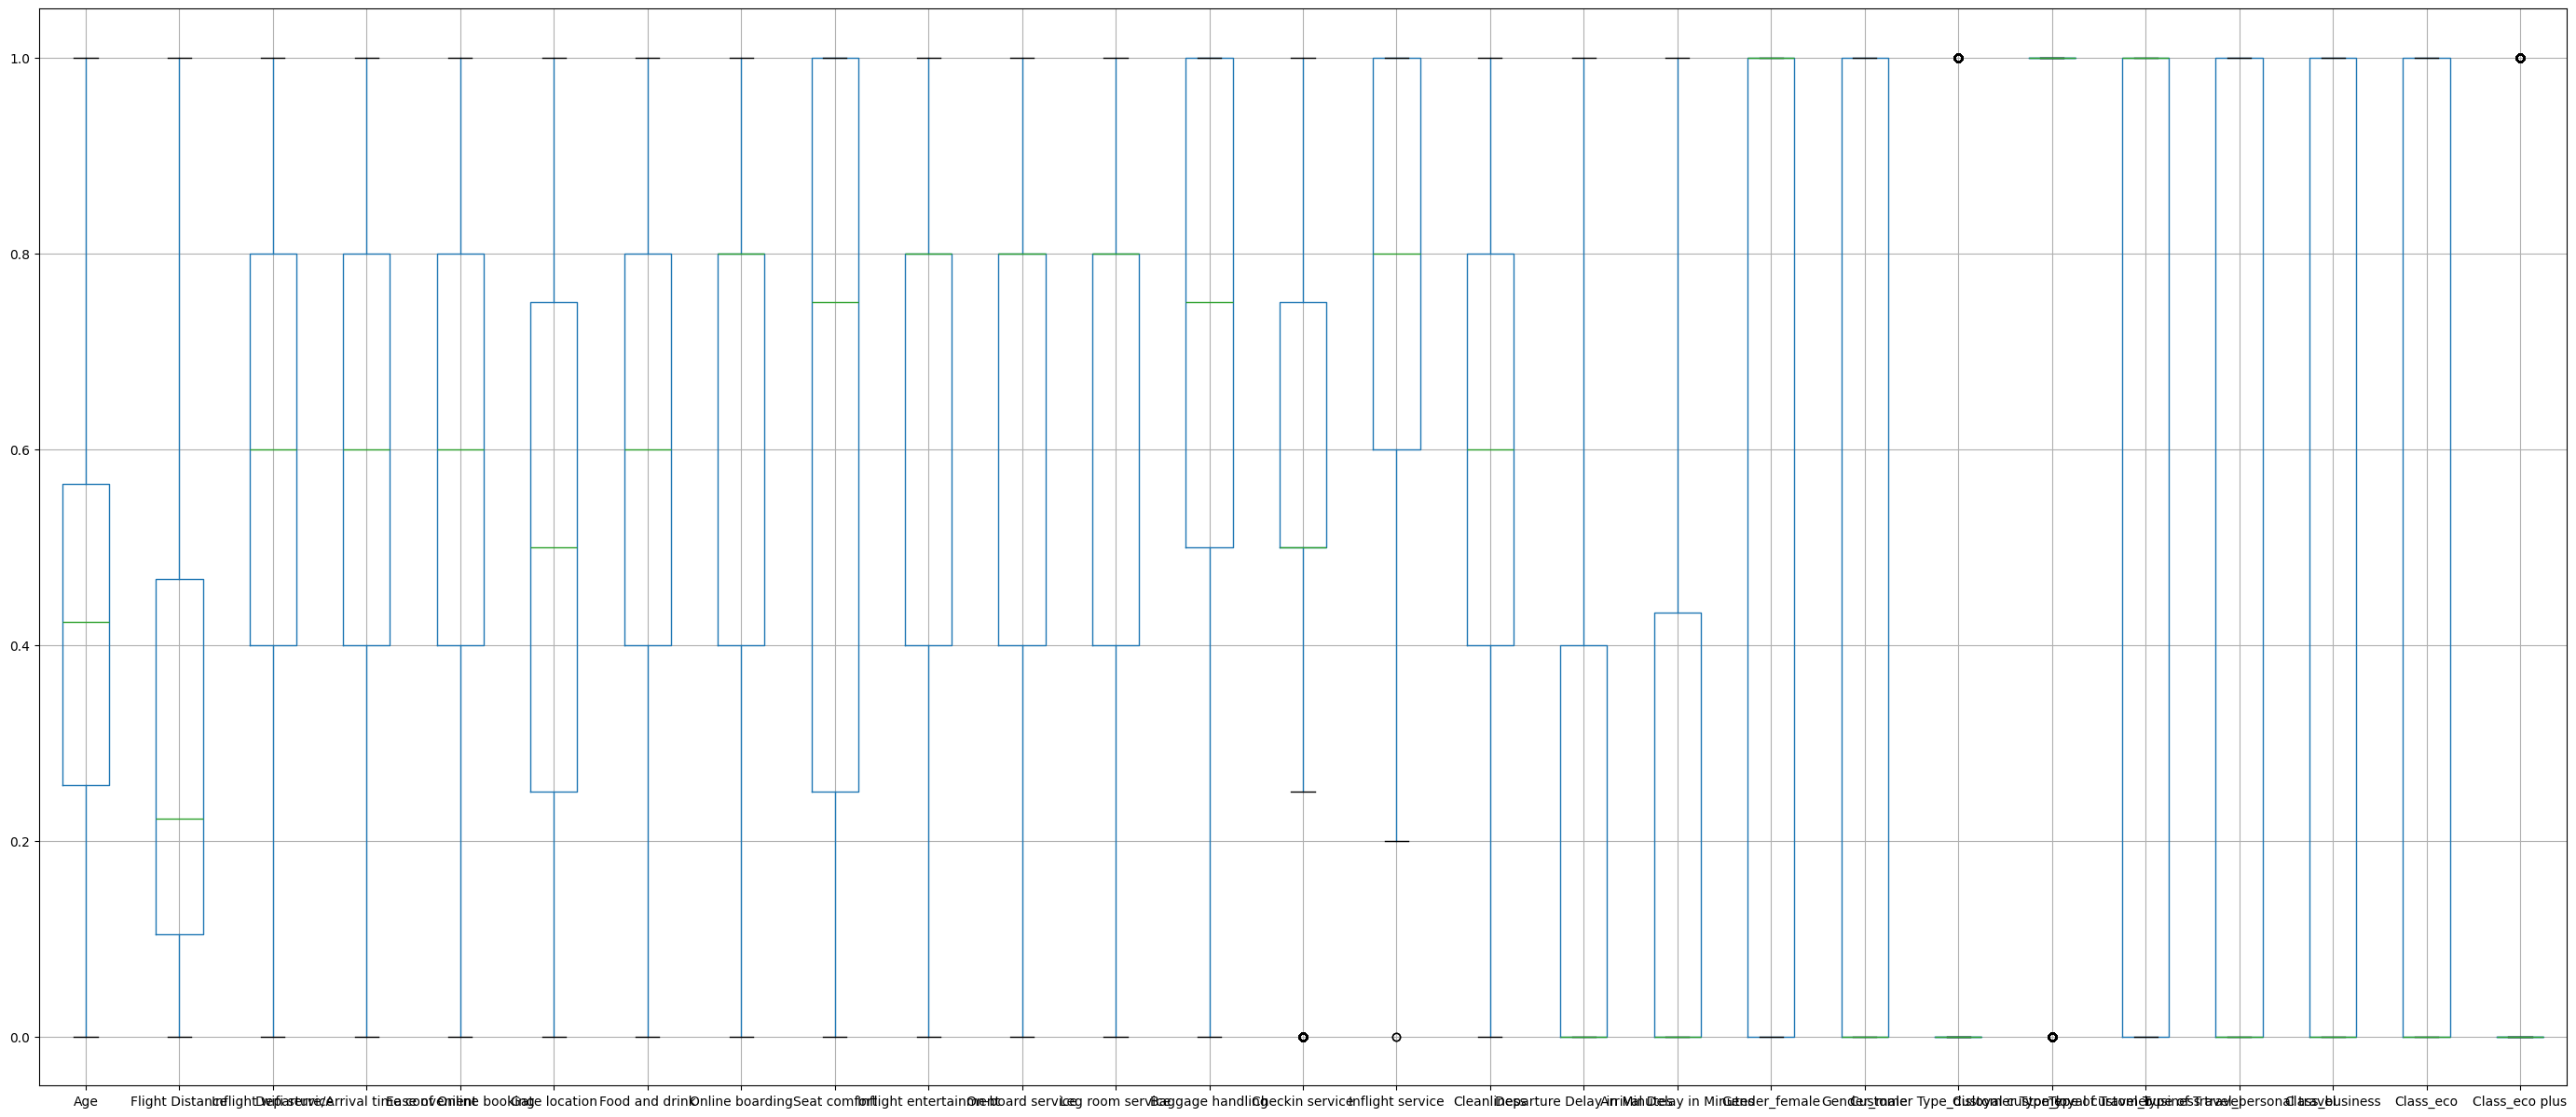

In [38]:
x.boxplot(figsize=(35,15))

#### An example of representing just one attribute

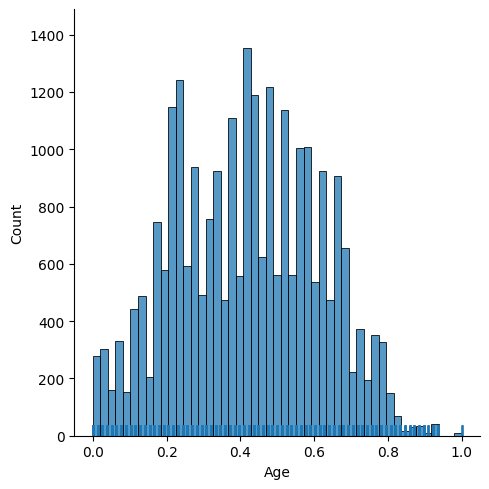

In [39]:
sns.displot(x["Age"],kde=False,rug=True)

<Axes: >

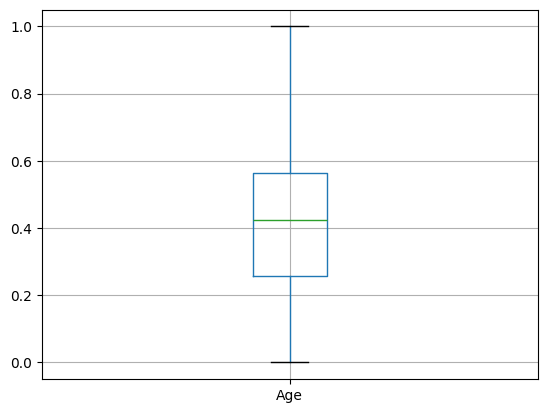

In [40]:
x.boxplot(column=["Age"])

In [41]:
x.describe()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Arrival Delay in Minutes,Gender_female,Gender_male,Customer Type_disloyal customer,Customer Type_loyal customer,Type of Travel_business travel,Type of Travel_personal travel,Class_business,Class_eco,Class_eco plus
count,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000,...,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000,25893.000000
mean,0.418231,0.315685,0.544742,0.609284,0.551199,0.494110,0.642985,0.652323,0.612221,0.671394,...,0.252748,0.506971,0.493029,0.184683,0.815317,0.694396,0.305604,0.481095,0.445062,0.073842
std,0.194029,0.268860,0.266942,0.306594,0.282510,0.320415,0.266379,0.271101,0.330064,0.267729,...,0.376511,0.499961,0.499961,0.388048,0.388048,0.460672,0.460672,0.499652,0.496982,0.261519
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.256410,0.104388,0.400000,0.400000,0.400000,0.250000,0.400000,0.400000,0.250000,0.400000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.423077,0.222949,0.600000,0.600000,0.600000,0.500000,0.600000,0.800000,0.750000,0.800000,...,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
75%,0.564103,0.466885,0.800000,0.800000,0.800000,0.750000,0.800000,0.800000,1.000000,0.800000,...,0.433333,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [42]:
x.shape

(25893, 27)

#### Save attributes matrix *x* and target labels *t* to csv files.

In [43]:
x.to_csv (ATT_FILE_NAME, index=False)
binary_t.to_csv(BINARY_ENCODED_CLASSES_FILE_NAME, index=False)